# Chapter 6 — Information Diffusion

## Why this chapter matters

These methods turn social-media traces into careful, measurable evidence without treating posts as the whole population.

## Learning outcomes

- Reconstruct and measure cascades.
- Compare Independent Cascade and Linear Threshold simulations.

## Concepts in simple language

Diffusion describes adoption after exposure. A cascade has a seed/root, reshares, size, depth, duration and speed. Independent Cascade gives active nodes one probabilistic chance; Linear Threshold activates after enough active-neighbor influence. Simulations are assumptions, not forecasts.

## Dataset introduction

`diffusion_events.csv` records small synthetic cascades and parent links. All data are synthetic teaching data; they contain no real private users.

In [1]:
from pathlib import Path
import random, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RANDOM_SEED = 42
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
current_path = Path.cwd()
if (current_path / 'data').exists(): repository_root = current_path
elif (current_path.parent / 'data').exists(): repository_root = current_path.parent
else: raise FileNotFoundError('Could not find the repository data directory.')
data_directory = repository_root / 'data'
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('Data directory:', data_directory)


Python: 3.9.6 | pandas: 2.2.3
Data directory: /Users/mehrdadjalali/Documents/SRH-Courses/Modules/Social Media Analytics and Sentiment Analysis/Github/SocialMediaAnayltics/data


,size,start,end,misinformation,duration_minutes
cascade_id,,,,,
c1,9,2025-03-01,2025-03-01 00:56:00,False,56.0
c2,10,2025-03-02,2025-03-02 01:03:00,False,63.0
c3,11,2025-03-03,2025-03-03 01:10:00,True,70.0
c4,12,2025-03-04,2025-03-04 01:17:00,False,77.0
c5,13,2025-03-05,2025-03-05 01:24:00,False,84.0
c6,14,2025-03-06,2025-03-06 01:31:00,True,91.0
c7,15,2025-03-07,2025-03-07 01:38:00,False,98.0
c8,16,2025-03-08,2025-03-08 01:45:00,False,105.0


,cascade_id,user_id,timestamp
0,c1,u01,2025-03-01
9,c2,u06,2025-03-02
19,c3,u11,2025-03-03
30,c4,u16,2025-03-04
42,c5,u21,2025-03-05
55,c6,u26,2025-03-06
69,c7,u31,2025-03-07
84,c8,u36,2025-03-08


c8 DiGraph with 16 nodes and 15 edges


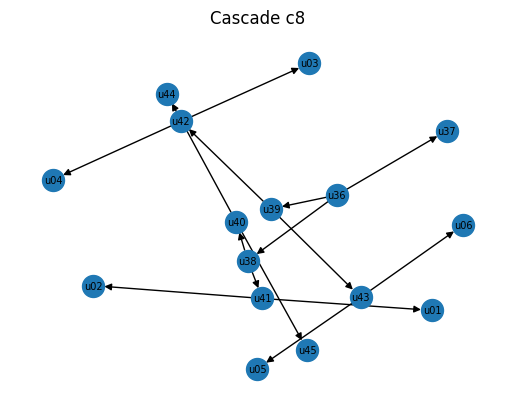

In [2]:
import networkx as nx
events=pd.read_csv(data_directory/'diffusion_events.csv',parse_dates=['timestamp']); roots=events[events['parent_user_id'].isna()]
summary=events.groupby('cascade_id').agg(size=('user_id','size'),start=('timestamp','min'),end=('timestamp','max'),misinformation=('is_misinformation','first')); summary['duration_minutes']=(summary.end-summary.start).dt.total_seconds()/60
display(summary); display(roots[['cascade_id','user_id','timestamp']])
cid=summary['size'].idxmax(); ce=events[events.cascade_id==cid]; cascade=nx.DiGraph(); cascade.add_nodes_from(ce.user_id); cascade.add_edges_from(ce.dropna(subset=['parent_user_id'])[['parent_user_id','user_id']].itertuples(index=False,name=None)); print(cid,cascade)
pos=nx.spring_layout(cascade,seed=RANDOM_SEED); nx.draw_networkx(cascade,pos,node_size=250,font_size=7,arrows=True); plt.title(f'Cascade {cid}'); plt.axis('off'); plt.show()

## Instructor-guided walkthrough

We reconstruct observed cascades, visualize a cascade, implement two validated simulations, and compare seed strategies and probabilities.

## Step-by-step Python implementation

### Function guide: `independent_cascade`

**Library:** custom  
**Purpose:** Simulate probabilistic activation rounds.  
**Input/return:** Takes the objects shown below and returns the stated result.  
**Common mistake:** Interpreting a score as causal proof.  
**Simple example:** See the next small code cell.

| Parameter | Value used | Meaning | What happens if changed? |
|---|---:|---|---|
| seed_nodes | list | Initially active users | More/better seeds may increase reach |
| activation_probability | 0.2 | Chance per active edge | Higher usually increases spread |
| max_steps | 10 | Round cap | Lower can truncate spread |
| random_seed | 42 | Reproducible draws | Another seed changes one realization |

In [3]:
def independent_cascade(graph: nx.Graph, seed_nodes: list[str], activation_probability: float=.2, max_steps: int=10, random_seed: int=42) -> list[set[str]]:
    """Return cumulative active-node sets by step under Independent Cascade.

    Validates seeds, probability and step count; a local RNG makes runs reproducible.
    """
    if not 0<=activation_probability<=1: raise ValueError('activation_probability must be in [0,1]')
    if max_steps<0: raise ValueError('max_steps must be non-negative')
    if not set(seed_nodes)<=set(graph): raise ValueError('all seed_nodes must be in graph')
    rng=random.Random(random_seed); active=set(seed_nodes); frontier=set(seed_nodes); history=[set(active)]
    for _ in range(max_steps):
        new={v for u in frontier for v in graph.neighbors(u) if v not in active and rng.random()<activation_probability}
        if not new: break
        active|=new; frontier=new; history.append(set(active))
    return history
def linear_threshold(graph: nx.Graph, seed_nodes: list[str], threshold: float=.3, max_steps: int=10) -> list[set[str]]:
    """Return cumulative active sets; activate when active-neighbor share reaches threshold."""
    if not 0<=threshold<=1: raise ValueError('threshold must be in [0,1]')
    if max_steps<0 or not set(seed_nodes)<=set(graph): raise ValueError('invalid steps or seeds')
    active=set(seed_nodes); history=[set(active)]
    for _ in range(max_steps):
        new={u for u in graph if u not in active and graph.degree(u)>0 and sum(v in active for v in graph.neighbors(u))/graph.degree(u)>=threshold}
        if not new: break
        active|=new; history.append(set(active))
    return history

In [4]:
edge_data=pd.read_csv(data_directory/'social_network_edges.csv'); social=nx.from_pandas_edgelist(edge_data,'source','target')
degree_seeds=[u for u,_ in sorted(social.degree,key=lambda x:x[1],reverse=True)[:2]]; random_seeds=random.Random(RANDOM_SEED).sample(list(social),2)
rows=[]
for seeds_name,seeds in [('degree',degree_seeds),('random',random_seeds)]:
    for probability in [.1,.2,.4]: rows.append([seeds_name,probability,len(independent_cascade(social,seeds,probability,10,RANDOM_SEED)[-1])])
display(pd.DataFrame(rows,columns=['seed_strategy','activation_probability','final_reach']))
print('Linear threshold reach:',len(linear_threshold(social,degree_seeds,threshold=.3,max_steps=10)[-1]))

,seed_strategy,activation_probability,final_reach
0,degree,0.1,7
1,degree,0.2,11
2,degree,0.4,36
3,random,0.1,6
4,random,0.2,9
5,random,0.4,30


Linear threshold reach: 31


## Output interpretation

Read values in context: inspect examples, sample sizes, uncertainty, and possible bias. Association is not causation.

## Common mistakes

Common errors include ignoring missing data, leakage, class imbalance, direction of edges, and treating model confidence as research certainty.

## Challenge 1: Measure and compare real cascade statistics

**Objective:** Apply a method demonstrated above.

**Tasks:** Adapt the starter code, check the result, and write two evidence-based sentences.

**Starter code:** `# result = ...`

**Hint:** Reuse the named columns and functions from the walkthrough.

**Expected output:** A small table or metric with no missing explanation.

**Interpretation question:** What does the result support, and what can it not prove?

**Self-check:** Did you report the sample size, units, and one limitation?

## Challenge 2: Test three activation probabilities

**Objective:** Apply a method demonstrated above.

**Tasks:** Adapt the starter code, check the result, and write two evidence-based sentences.

**Starter code:** `# result = ...`

**Hint:** Reuse the named columns and functions from the walkthrough.

**Expected output:** A small table or metric with no missing explanation.

**Interpretation question:** What does the result support, and what can it not prove?

**Self-check:** Did you report the sample size, units, and one limitation?

## Challenge 3: Compare random, degree and PageRank seeds

**Objective:** Apply a method demonstrated above.

**Tasks:** Adapt the starter code, check the result, and write two evidence-based sentences.

**Starter code:** `# result = ...`

**Hint:** Reuse the named columns and functions from the walkthrough.

**Expected output:** A small table or metric with no missing explanation.

**Interpretation question:** What does the result support, and what can it not prove?

**Self-check:** Did you report the sample size, units, and one limitation?

## Chapter summary

The walkthrough connected a research question to transparent data preparation, analysis, visual evidence, and cautious interpretation.

## Connection to the group project

Report simulation assumptions and distributions across repeated seeds, not one run as prediction.